# 10 · O sistema inteiro: arquitetura, observabilidade e o ciclo de feedback

> **Capítulo 10 do livro:** *AI Engineering Architecture and User Feedback*.
> Um modelo isolado não é um produto. O produto é o **sistema** em volta dele: quem recebe o pedido, o que é respondido sem modelo, o que o protege, o que registra, e como aprende com o uso.

**Objetivo:** montar, com as peças dos capítulos anteriores, um assistente de perguntas de OEE com **roteamento, cache, regras, guardas e escalonamento**; medir o que **cada componente** contribui; registrar **traços**; interpretar o **feedback dos operadores** (que é enviesado); fechar o ciclo com um **portão de regressão**; e **detectar deriva**.

## Antes de começar

- **Você precisa saber:** capítulos 4 (avaliação e regras), 5 (guardas) e 9 (cache).
- **O que é simulado:** o assistente é o **simulado do capítulo 4** (sabe a resposta e erra ao acaso por tipo de pergunta). Os custos e latências por componente são **assumidos**. **Os operadores são simulados** com vieses conhecidos, justamente para podermos comparar o que o feedback diz com a verdade. Dados 100 % sintéticos.
- **Tempo:** 70 minutos.

## Mapa do notebook

1. A arquitetura
2. O sistema rodando, e o que cada parte contribui
3. Observabilidade: o traço
4. Feedback dos operadores: o que ele diz e o que esconde
5. Fechando o ciclo: do feedback à nova versão, com portão de regressão
6. Deriva: quando o mundo muda
7. Implantação segura
8. A trilha inteira em uma tabela

In [1]:
import sys, pathlib, random
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
%matplotlib inline
import matplotlib.pyplot as plt

## 1. A arquitetura

Um pedido atravessa uma sequência de **decisões baratas antes da cara**:

1. **Cache:** já respondi isso? (capítulo 9: chave estruturada)
2. **Regras:** dá para calcular com código? (capítulo 4: o que é calculável não precisa de modelo)
3. **Assistente (modelo):** só o que sobrou.
4. **Guardas na saída:** a resposta tem formato válido, está no intervalo, não vaza instruções? (capítulo 5)
5. **Escalonamento:** se o sistema não sabe ou foi bloqueado, **passa para uma pessoa** em vez de inventar.

Em volta, três coisas que não são o fluxo mas decidem se o sistema melhora: **traço** (registro de cada pedido), **feedback** (o que os operadores dizem) e **avaliação** (o conjunto de regressão que barra versões piores).

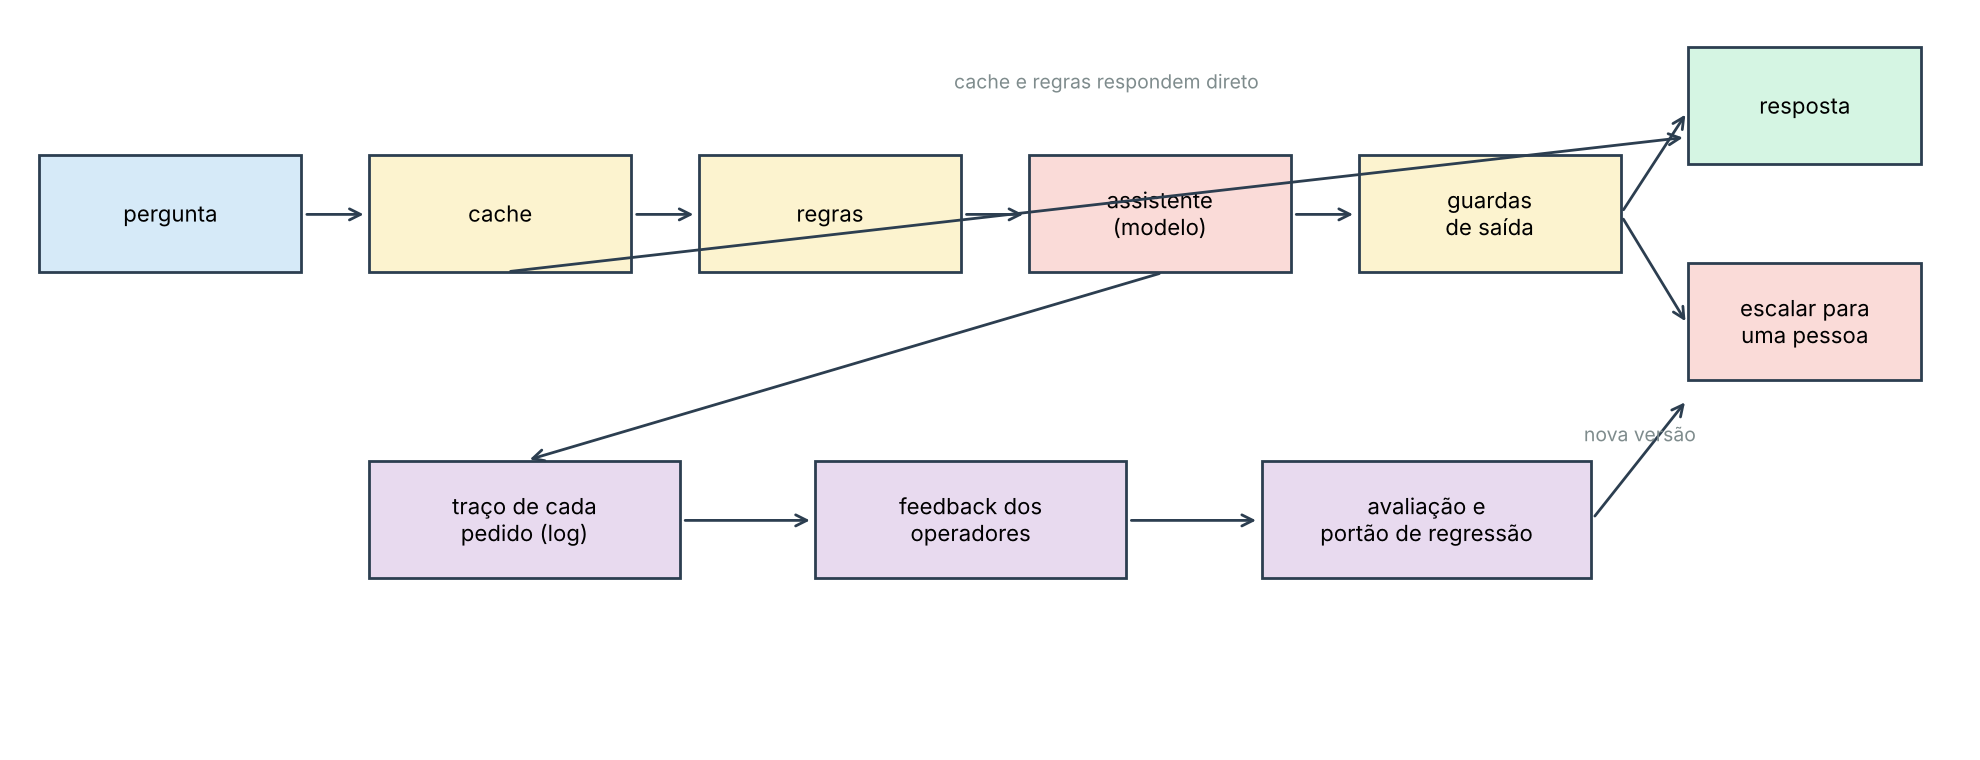

In [2]:
from aiind.system import *
from aiind.oeeqa import make_data, build_questions, wilson, paired_bootstrap
import numpy as np, random, json
from collections import Counter
fig, ax = plt.subplots(figsize=(10, 3.9)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 4)
def box(x, y, t, c="#ecf0f1", w=1.35, h=0.65):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc=c, ec="#2c3e50", lw=1)); ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", fontsize=8)
def arrow(x1, y1, x2, y2, t=""):
    ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="->", color="#2c3e50"))
    if t: ax.text((x1 + x2) / 2, (y1 + y2) / 2 + .1, t, fontsize=7, ha="center", color="#7f8c8d")
for x, t, c in [(0.1, "pergunta", "#d6eaf8"), (1.8, "cache", "#fcf3cf"), (3.5, "regras", "#fcf3cf"), (5.2, "assistente\n(modelo)", "#fadbd8"), (6.9, "guardas\nde saída", "#fcf3cf")]:
    box(x, 2.6, t, c)
for a, b in [(0.1, 1.8), (1.8, 3.5), (3.5, 5.2), (5.2, 6.9)]:
    arrow(a + 1.35, 2.92, b, 2.92)
box(8.6, 3.2, "resposta", "#d5f5e3", 1.2); box(8.6, 2.0, "escalar para\numa pessoa", "#fadbd8", 1.2)
arrow(8.25, 2.92, 8.6, 3.5); arrow(8.25, 2.92, 8.6, 2.3)
arrow(2.5, 2.6, 8.6, 3.35, ""); ax.text(5.6, 3.62, "cache e regras respondem direto", fontsize=7, color="#7f8c8d", ha="center")
box(1.8, 0.9, "traço de cada\npedido (log)", "#e8daef", 1.6); box(4.1, 0.9, "feedback dos\noperadores", "#e8daef", 1.6); box(6.4, 0.9, "avaliação e\nportão de regressão", "#e8daef", 1.7)
arrow(5.9, 2.6, 2.6, 1.55); arrow(3.4, 1.22, 4.1, 1.22); arrow(5.7, 1.22, 6.4, 1.22); arrow(8.1, 1.22, 8.6, 1.9, "nova versão")
plt.tight_layout()

## 2. O sistema rodando, e o que cada parte contribui

Usamos as 300 perguntas do capítulo 4, **repetidas duas vezes** (um dia de operação tem perguntas repetidas). Medimos três resultados que importam mais que "acurácia":

- **certo:** a resposta certa (ou o encaminhamento certo quando faltam dados);
- **escalado:** o sistema não respondeu e passou para uma pessoa (**seguro, mas custa tempo de gente**);
- **erro mostrado:** uma **resposta errada chegou ao operador**. É o número que mais machuca.

Depois **desligamos um componente por vez** para ver o que cada um faz.

In [3]:
data = make_data(5); qs = build_questions(data, 300, 21); dia = qs + qs
variantes = {"sistema completo (v1)": {}, "sem cache": dict(use_cache=False), "sem regras": dict(use_rules=False), "sem guardas": dict(use_guard=False),
             "só o assistente": dict(use_cache=False, use_rules=False, use_guard=False)}
print(f"{'variante':24s} {'certo':>6s} {'escalado':>9s} {'erro mostrado':>14s} {'lat. média':>11s} {'lat. p95':>9s} {'US$ por mil':>12s}   rotas")
for nome, kw in variantes.items():
    ev = run(System(data, **kw), dia); s = summarize(ev); rotas = Counter(e.route for e in ev)
    print(f"{nome:24s} {s['certo']:6.0%} {s['escalado']:9.0%} {s['erro mostrado']:14.1%} {s['latência média']:10.2f}s {s['latência p95']:8.2f}s {s['custo por mil']:12.3f}   " + ", ".join(f"{r} {rotas[r]}" for r in ('cache', 'regras', 'assistente', 'escalado')))

variante                  certo  escalado  erro mostrado  lat. média  lat. p95  US$ por mil   rotas
sistema completo (v1)       80%       12%           7.7%       0.40s     1.42s        0.254   cache 318, regras 113, assistente 88, escalado 81
sem cache                   80%       14%           6.3%       0.69s     1.42s        0.435   cache 0, regras 310, assistente 198, escalado 92
sem regras                  62%       23%          15.3%       0.78s     1.41s        0.495   cache 270, regras 0, assistente 163, escalado 167
sem guardas                 88%        0%          11.7%       0.30s     1.41s        0.188   cache 362, regras 113, assistente 121, escalado 4
só o assistente             80%        0%          19.7%       1.40s     1.40s        0.900   cache 0, regras 0, assistente 580, escalado 20


### Pare e preveja

Qual componente mais reduz o **erro mostrado**? Qual mais reduz o **custo**? Algum deles piora algum número?

Pela tabela:

- **Regras** são o maior ganho: sem elas o erro mostrado dobra (15,3 % contra 7,7 %), o custo quase dobra, e com o assistente sozinho 20 % das respostas mostradas estão erradas. A maior parte das perguntas é calculável (capítulo 4).
- **Guardas** trocam erro por escalonamento: sem elas, o erro mostrado sobe de 7,7 % para 11,7 %; com elas, parte desses casos vira "passar para uma pessoa" (11,8 %). **Não existe resposta grátis**: o que você deixa de mostrar errado vira trabalho humano.
- **Cache** corta o custo em ~40 % (US$ 0,25 contra 0,44 por mil) e a latência média também (0,40 contra 0,69 s), **mas repete respostas erradas também**: uma resposta errada guardada vira erro **a cada repetição**. O "erro mostrado" sobe um pouco com cache (7,7 % contra 6,3 %). Por isso só se guarda no cache o que **passou pelas guardas**, e é bom registrar a rota para poder invalidar.

## 3. Observabilidade: o traço

Sem registro, nada do que vem depois é possível. Cada pedido gera um **traço**: o que entrou, por qual rota passou, o que saiu, quanto custou, quanto demorou, se foi bloqueado e por quê. Um traço por linha (JSONL) basta para começar.

In [4]:
ev = run(System(data), dia)
for e in ev[:3]:
    print(json.dumps({"id": e.qid, "rota": e.route, "tipo": e.kind, "resposta": e.shown, "bloqueio": e.blocked, "latencia_s": round(e.latency, 3), "custo_usd": round(e.cost, 6)}, ensure_ascii=False))
rotas = Counter(e.route for e in ev); print()
print(f"{'rota':12s} {'pedidos':>8s} {'erro mostrado':>14s} {'lat. média':>11s} {'US$ por mil':>12s}")
for r in ("cache", "regras", "assistente", "escalado"):
    es = [e for e in ev if e.route == r]
    print(f"{r:12s} {len(es):8d} {np.mean([e.wrong_shown for e in es]):14.1%} {np.mean([e.latency for e in es]):10.3f}s {1000 * np.mean([e.cost for e in es]):12.3f}")

{"id": 0, "rota": "regras", "tipo": "falha", "resposta": "0", "bloqueio": "", "latencia_s": 0.013, "custo_usd": 0.0}
{"id": 1, "rota": "regras", "tipo": "pior", "resposta": "esteira", "bloqueio": "", "latencia_s": 0.013, "custo_usd": 0.0}
{"id": 2, "rota": "escalado", "tipo": "perda", "resposta": "não sei", "bloqueio": "formato fora do esperado", "latencia_s": 1.423, "custo_usd": 0.0009}

rota          pedidos  erro mostrado  lat. média  US$ por mil
cache             318           9.1%      0.003s        0.000
regras            113           0.0%      0.013s        0.000
assistente         88          19.3%      1.423s        0.900
escalado           81           0.0%      1.423s        0.900


O painel mínimo de um sistema destes:

- **por rota:** volume, erro, latência (p50, p95) e custo;
- **taxa de escalonamento** e **motivos de bloqueio** das guardas;
- **tipo de pergunta**, para ver onde falha;
- **versão** do sistema, do prompt e dos dados em cada traço (reprodutibilidade).

**Privacidade:** o texto livre de operador pode conter nomes e identificadores (capítulo 8). Decida o que se registra, por quanto tempo, e quem acessa. Registrar **a rota e o tipo** costuma bastar para a maioria das análises.

## 4. Feedback dos operadores: o que ele diz e o que esconde

O feedback chega de três formas: **explícito** (polegar para cima ou para baixo), **implícito** (o operador **reformula** a pergunta logo depois, ou **escala** para uma pessoa), e **auditoria** (um especialista confere uma amostra). Cada um tem um viés.

Simulamos operadores com viés **conhecido**: percebem 85 % dos erros, reclamam muito mais do que elogiam (35 % dos que percebem um erro dão polegar para baixo; só 5 % dos que acham certo dão para cima), e às vezes reformulam. Como conhecemos a verdade, podemos medir o quanto o feedback **engana**.

In [5]:
stream = dia * 2
ev = run(System(data), stream); sig = operator_feedback(ev, 1)
ups = sum(s.thumb == "up" for s in sig); downs = sum(s.thumb == "down" for s in sig)
verdade = np.mean([e.ok for e in ev])
print(f"{len(ev)} pedidos | polegares: {ups} para cima, {downs} para baixo ({(ups + downs) / len(ev):.0%} dos pedidos geraram polegar)")
print(f"'taxa de aprovação' pelos polegares: {ups / (ups + downs):.0%}   |   acerto verdadeiro: {verdade:.0%}")
aud = audit_sample(ev, 100, 0); k = sum(e.ok for e in aud); lo, hi = wilson(k, 100)
print(f"auditoria de 100 pedidos sorteados: {k / 100:.0%}  (intervalo de 95 %: {lo:.0%} a {hi:.0%})")

1200 pedidos | polegares: 49 para cima, 83 para baixo (11% dos pedidos geraram polegar)
'taxa de aprovação' pelos polegares: 37%   |   acerto verdadeiro: 81%
auditoria de 100 pedidos sorteados: 79%  (intervalo de 95 %: 70% a 86%)


Os polegares dizem **37 % de aprovação** quando o acerto verdadeiro é **81 %**. O motivo é a **seleção**: quem reclama aparece, quem está satisfeito fica calado. Usar a taxa de polegares como acurácia é um erro de **viés de seleção**.

A **auditoria por amostra aleatória** é pequena, mas **sem viés**, e vem com intervalo. Regra prática: **polegares dizem onde olhar; a amostra auditada diz quanto**.

Onde olhar? Cortamos o sinal negativo (polegar para baixo ou reformulação) por tipo e por forma da pergunta, e comparamos com o que realmente acontece:

In [6]:
def neg(s): return s.thumb == "down" or s.reask
print(f"{'tipo':8s} {'sinal negativo':>15s} {'erro mostrado real':>19s} {'escalado real':>14s}")
for kind in ("pecas", "falha", "oee", "pior", "perda"):
    ss = [s for s in sig if s.event.kind == kind]; es = [s.event for s in ss]
    print(f"{kind:8s} {np.mean([neg(s) for s in ss]):15.0%} {np.mean([e.wrong_shown for e in es]):19.0%} {np.mean([e.abstained for e in es]):14.0%}")
print(f"\n{'forma':8s} {'sinal negativo':>15s} {'certo real':>11s} {'rota assistente ou escalado':>28s}")
for t in range(3):
    ss = [s for s in sig if s.event.template == t]; es = [s.event for s in ss]
    print(f"{'frase ' + str(t + 1):8s} {np.mean([neg(s) for s in ss]):15.0%} {np.mean([e.ok for e in es]):11.0%} {np.mean([e.route in ('assistente', 'escalado') for e in es]):28.0%}")

tipo      sinal negativo  erro mostrado real  escalado real
pecas                18%                  4%             4%
falha                18%                  1%            12%
oee                  18%                  4%             8%
pior                 20%                  7%             6%
perda                27%                 20%            23%

forma     sinal negativo  certo real  rota assistente ou escalado
frase 1              16%         95%                           6%
frase 2              17%         89%                           8%
frase 3              28%         60%                          45%


O sinal negativo aponta as **mesmas regiões** que o erro real: o tipo **perda** (o assistente erra 20 % e escala 23 %) e a **frase 3** ("Peças boas da prensa no 3º dia?"), onde só 60 % saem certas e 45 % não passam pelas regras. A análise de causa é a seguinte: **o analisador (parser) das regras não entende "3º dia"**, então essas perguntas caem no assistente, que é mais caro e erra mais. É uma correção de código, não de modelo.

Dois cuidados: o sinal é **ruidoso** (por isso se junta volume, e se confirma com auditoria), e **escalonar não é fracasso**: é o sistema funcionando. O fracasso é o erro que **passou calado**.

## 5. Fechando o ciclo: do feedback à nova versão, com portão de regressão

O ciclo: **feedback → hipótese → correção → avaliar → implantar**. A correção da v2: o analisador entende "3º dia" e a pergunta de **perda**, e passa a aceitar "ontem" (os operadores começaram a perguntar assim; os 200 casos novos abaixo representam o que apareceu nos traços).

Antes de implantar, o **portão de regressão** compara v1 e v2 **nas mesmas perguntas** (diferença emparelhada, com intervalo), em **três conjuntos**: o de avaliação fixo (cap. 4), os **casos de produção** (formas novas de perguntar), e por **fatia**. A regra: melhora no total **e nenhuma fatia pior**.

In [7]:
nov = novel_questions(data, 200, 1)
def avalia(sys_a, sys_b, qs_, nome):
    a = [e.ok for e in run(sys_a, qs_)]; b = [e.ok for e in run(sys_b, qs_)]
    d, lo, hi = paired_bootstrap(b, a)
    print(f"{nome:44s} v1 {np.mean(a):5.0%} | v2 {np.mean(b):5.0%} | diferença {d:+6.1%}  [{lo:+.1%}, {hi:+.1%}]")
    return d, lo
avalia(System(data, 1), System(data, 2), qs, "avaliação fixa (300 perguntas, cap. 4)")
avalia(System(data, 1), System(data, 2), nov, "casos de produção (200, forma nova: 'ontem')")
print("\npor tipo, avaliação fixa:")
for kind in ("pecas", "falha", "oee", "pior", "perda"):
    sub = [q for q in qs if q.asked == kind]; avalia(System(data, 1), System(data, 2), sub, f"   {kind} ({len(sub)})")

avaliação fixa (300 perguntas, cap. 4)       v1   80% | v2  100% | diferença +20.3%  [+15.7%, +25.0%]


casos de produção (200, forma nova: 'ontem') v1   72% | v2  100% | diferença +28.0%  [+22.0%, +34.0%]

por tipo, avaliação fixa:
   pecas (49)                                v1   92% | v2  100% | diferença  +8.2%  [+2.0%, +16.3%]
   falha (73)                                v1   84% | v2  100% | diferença +16.4%  [+8.2%, +26.0%]
   oee (51)                                  v1   88% | v2  100% | diferença +11.8%  [+3.9%, +21.6%]
   pior (57)                                 v1   86% | v2  100% | diferença +14.0%  [+5.3%, +22.8%]


   perda (70)                                v1   56% | v2  100% | diferença +44.3%  [+32.9%, +57.1%]


A v2 melhora **em todos os tipos** e nos casos novos, com intervalos que não incluem zero: passa no portão. Isso é esperado, porque aqui as perguntas são **calculáveis**: onde o código sabe, ele supera o modelo (capítulo 4). Numa pergunta aberta, o assistente continuaria como último recurso.

O portão existe para barrar o contrário. Uma "otimização" plausível: **uma v2 com um erro de implementação no cache** (a chave esquece a máquina, então a resposta de uma máquina é devolvida para outra). Se o teste só exercita a lógica de resposta (cache desligado), ninguém vê. Rodando o **sistema completo**, com o cache ligado:

In [8]:
for nome, sy in {"v1": System(data, 1), "v2": System(data, 2), "v2 com cache sem a máquina na chave": System(data, 2, cache_bug=True)}.items():
    s1 = summarize(run(System(data, sy.version, use_cache=False), dia)); s2 = summarize(run(System(data, sy.version, cache_bug=sy.cache_bug), dia))
    print(f"{nome:40s} teste da lógica (cache desligado): certo {s1['certo']:5.0%}, erro mostrado {s1['erro mostrado']:5.1%} | sistema completo: certo {s2['certo']:5.0%}, erro mostrado {s2['erro mostrado']:5.1%}")

v1                                       teste da lógica (cache desligado): certo   80%, erro mostrado  6.3% | sistema completo: certo   80%, erro mostrado  7.7%
v2                                       teste da lógica (cache desligado): certo  100%, erro mostrado  0.0% | sistema completo: certo  100%, erro mostrado  0.0%
v2 com cache sem a máquina na chave      teste da lógica (cache desligado): certo  100%, erro mostrado  0.0% | sistema completo: certo   67%, erro mostrado 32.7%


O candidato com o bug **é perfeito** no teste da lógica e **cai para 67 %** (33 % de erros mostrados) no sistema completo. Lições para o portão:

- **Teste o sistema inteiro, com todos os componentes ligados**, e com um conjunto que se parece com a operação (repetições, formas novas de perguntar), não só a lógica isolada.
- Olhe **erro mostrado**, não só "certo": o sistema que escala tudo também tem 0 % de erro.
- O portão roda **automaticamente** a cada mudança de prompt, de modelo, de regra, de dado (como o CI deste repositório roda os testes).

Cada **caso de produção** que revelou um problema vira **caso permanente** do conjunto de avaliação (com a resposta confirmada por um especialista): é assim que o conjunto cresce e fica parecido com a realidade (capítulo 8).

## 6. Deriva: quando o mundo muda

Depois de implantado, o mundo muda: os operadores passam a perguntar de outro jeito, entra uma máquina nova, o dado muda de formato. O sistema não "quebra"; **piora devagar**. Simulamos 8 semanas com a v1: a partir da semana 5, uma parte crescente das perguntas passa a usar "ontem". Quatro medidas por semana:

- **Fora do vocabulário das regras:** a parcela de perguntas que o analisador não reconhece. **Não precisa de rótulo**, então avisa cedo.
- **Sinal negativo dos operadores:** polegar para baixo ou reformulação.
- **Auditoria** de 60 pedidos sorteados na semana.
- **Erro mostrado real** (só conhecemos porque é simulação).

Cada uma tem **limites de controle** (3 desvios, calculados com as 4 primeiras semanas, como no alarme do capítulo 3).

medida                             s1     s2     s3     s4     s5     s6     s7     s8      primeiro alarme
fora do vocabulário das regras       34%    32%    34%    36%    43%    44%    58%    68%   semana 5
sinal negativo dos operadores        18%    20%    18%    20%    19%    22%    23%    23%   sem alarme
erro na auditoria (60/semana)         7%    10%     7%    10%    17%    12%    13%    22%   semana 8
erro mostrado real                    9%     9%     8%     7%    12%    12%    16%    20%   semana 6


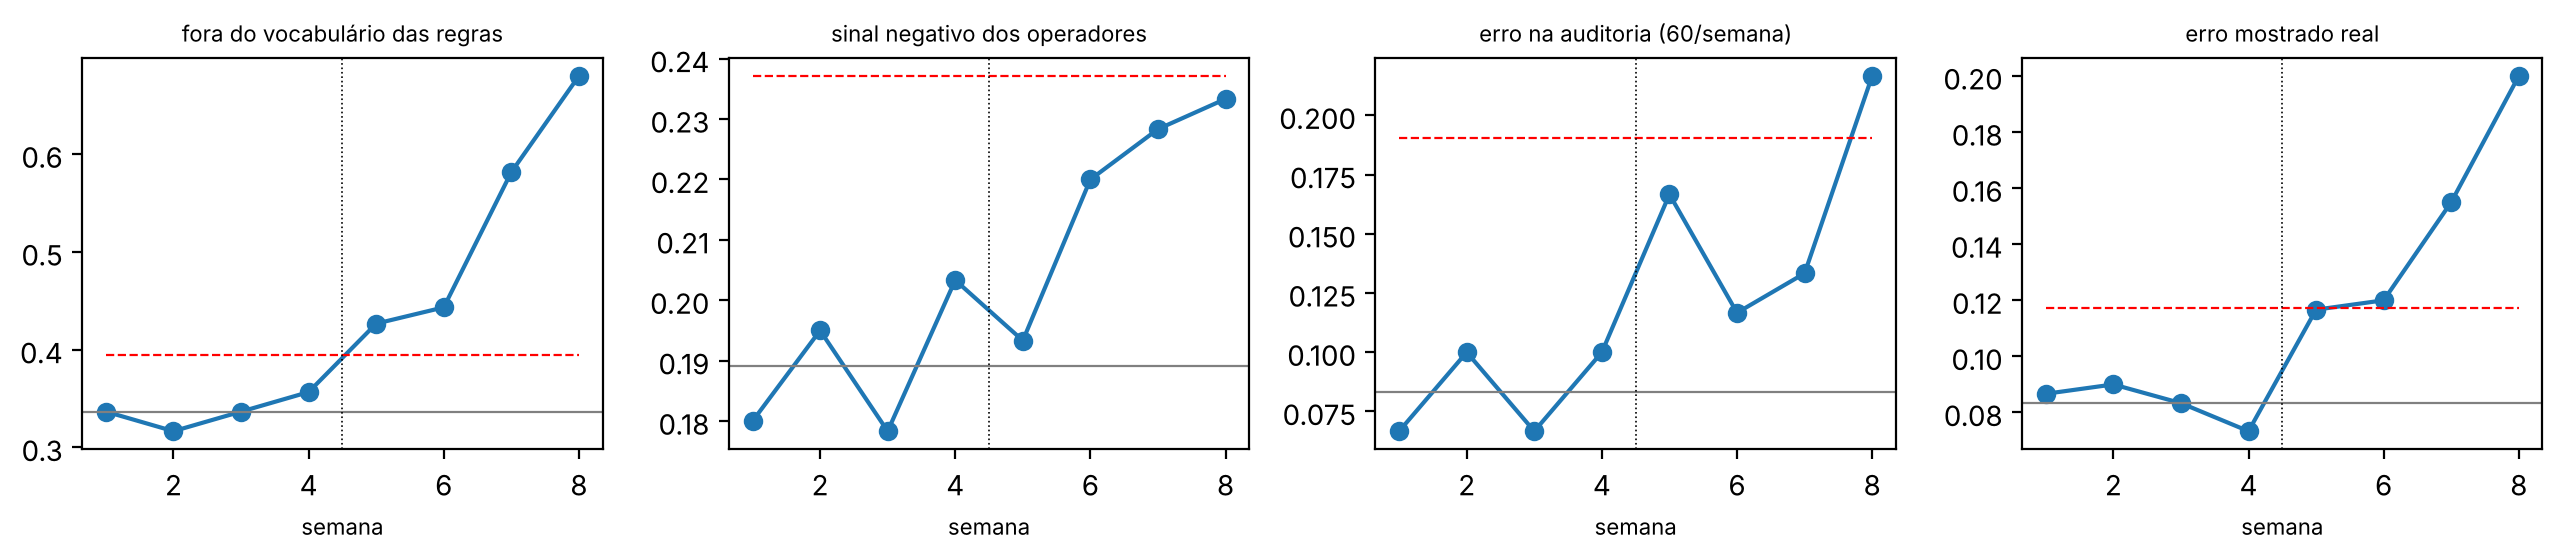

In [9]:
from aiind.oeeqa import parse
rng = random.Random(0); shares = [0, 0, 0, 0, 0.1, 0.2, 0.35, 0.5]; N = 600; semanas = []
for w, sh in enumerate(shares):
    base_ = build_questions(data, N, 100 + w); nv = novel_questions(data, N, 200 + w); qq = [nv[i] if rng.random() < sh else base_[i] for i in range(N)]
    evw = run(System(data), qq); sg = operator_feedback(evw, w); au = audit_sample(evw, 60, w)
    semanas.append(dict(fora=sum(parse(q.text) is None for q in qq), neg=sum(neg(s) for s in sg), aud=sum(e.wrong_shown for e in au), real=sum(e.wrong_shown for e in evw), n=[N, N, 60, N]))
series = {"fora do vocabulário das regras": ("fora", N), "sinal negativo dos operadores": ("neg", N), "erro na auditoria (60/semana)": ("aud", 60), "erro mostrado real": ("real", N)}
fig, axs = plt.subplots(1, 4, figsize=(13, 2.9)); print(f"{'medida':34s} " + " ".join(f"s{w + 1:<5d}" for w in range(8)) + "  primeiro alarme")
for ax, (nome, (k, n)) in zip(axs, series.items()):
    cnt = [s[k] for s in semanas]; p0, lo, hi = p_chart(cnt, [n] * 8); taxa = [c / n for c in cnt]; alarme = next((w + 1 for w, t in enumerate(taxa) if w >= 4 and t > hi[w]), None)
    ax.plot(range(1, 9), taxa, "o-"); ax.plot(range(1, 9), hi, "r--", lw=.8); ax.axhline(p0, c="gray", lw=.8); ax.axvline(4.5, c="k", ls=":", lw=.6); ax.set_title(nome, fontsize=8); ax.set_xlabel("semana", fontsize=8)
    print(f"{nome:34s} " + " ".join(f"{t:5.0%} " for t in taxa) + f"  semana {alarme}" if alarme else f"{nome:34s} " + " ".join(f"{t:5.0%} " for t in taxa) + "  sem alarme")
plt.tight_layout()

Com 600 pedidos por semana, o quadro é claro. A medida **sem rótulos** (parcela fora do vocabulário das regras) passa do limite **já na semana 5**, a primeira em que 10 % das perguntas mudam de forma, e continua subindo. O **erro real** (que na vida real você não conhece) só passa do limite na semana 6. A **auditoria** de 60 pedidos só acusa na semana 8: amostra pequena tem pouco poder. E o **sinal dos operadores nunca dispara** (de 18 % a 23 %): feedback é pouco sensível a esse tipo de mudança, porque muita pergunta nova cai no assistente, que acerta a maior parte delas.

A lição: **monitore a entrada** (barato, imediato, sem rótulo, e olha a causa antes do efeito) **e audite uma amostra** (para quantificar), sem depender só do feedback espontâneo. Quando o alarme dispara, o ciclo da seção 5 começa de novo: olhar os casos novos, corrigir (aqui, ensinar o analisador a entender "ontem"), passar pelo portão, implantar.

## 7. Implantação segura

Mesmo com portão, implante **em degraus**, com a possibilidade de voltar:

1. **Sombra (shadow):** a v2 roda em paralelo, **sem responder**, e compara com a v1 nos pedidos reais.
2. **Canário:** a v2 atende uma **pequena parcela** (5 %) dos operadores, com o painel da seção 3 dividido por versão.
3. **Aumento gradual** se as medidas se mantêm; **volta imediata** (rollback) se alguma passar do limite.
4. **Pessoa no circuito** para o que muda o mundo (capítulo 6): ordens de manutenção, mudanças de parâmetro.
5. **Registro da versão** em cada traço, para saber, depois, qual versão respondeu o quê.

Para um sistema numa planta, acrescente o que é de OT: **o sistema de IA não escreve em equipamento** sem camada de segurança e aprovação, **tem modo degradado** (se o modelo ou a rede cair, as regras e o painel continuam), e **o escalonamento tem um destino real** (quem recebe, em quanto tempo).

## Erros comuns

- **Tratar a taxa de polegares como acurácia.**
- **Não registrar traços**, e depois não conseguir explicar um erro.
- **Cachear respostas sem passar pelas guardas** (o erro vira permanente), ou com chave errada.
- **Medir "certo" e ignorar "erro mostrado"** e a carga de escalonamento.
- **Conjunto de regressão que não parece com a operação** (sem repetições, sem as formas novas de perguntar).
- **Só monitorar a qualidade** (que chega tarde) e não a **entrada**.
- **Implantar de uma vez**, sem sombra, canário nem rollback.
- **Colocar o modelo onde uma regra resolve.** Regras primeiro, modelo para o resto.
- **Esquecer que alguém recebe o que foi escalado.**

## Confira o que ficou

**1. Por que a arquitetura coloca cache e regras antes do modelo?**

<details><summary>Ver resposta</summary>

Porque são mais baratas, mais rápidas e mais confiáveis para o que é calculável; o modelo fica só com o que sobra.

</details>

**2. Escalar para uma pessoa é uma falha do sistema?**

<details><summary>Ver resposta</summary>

Não: é a saída segura quando o sistema não sabe ou foi bloqueado. A falha é a resposta errada que chega calada ao operador.

</details>

**3. Por que a taxa de polegares para cima não mede a acurácia?**

<details><summary>Ver resposta</summary>

Porque quem reclama dá feedback muito mais do que quem aprova (viés de seleção); a taxa fica bem abaixo do acerto verdadeiro.

</details>

**4. Se os polegares enganam, para que servem?**

<details><summary>Ver resposta</summary>

Para apontar onde olhar (tipos e formas de pergunta com mais sinal negativo). Quanto o sistema acerta, mede-se com uma amostra sorteada e auditada.

</details>

**5. O que um portão de regressão compara?**

<details><summary>Ver resposta</summary>

Duas versões nas mesmas perguntas, com diferença emparelhada e intervalo, no total, por fatia e em casos de produção; barra a versão que piora o total ou alguma fatia.

</details>

**6. Por que monitorar a entrada, e não só a qualidade?**

<details><summary>Ver resposta</summary>

A entrada muda antes de a qualidade cair, não exige rótulo e dá o alarme cedo; a qualidade exige auditoria e chega tarde.

</details>

**7. O que são sombra e canário?**

<details><summary>Ver resposta</summary>

Sombra: a nova versão roda em paralelo sem responder. Canário: ela atende uma pequena parcela dos usuários, com a possibilidade de voltar atrás.

</details>

## Exercícios

1. **Limiar das guardas:** a guarda de "OEE fora de 0 a 100" é uma entre várias. Escreva uma guarda nova (por exemplo, a resposta de peças não pode ser maior que a capacidade teórica do dia) e meça o que ela bloqueia e se bloqueia algum acerto.
2. **Custo do escalonamento:** atribua um custo de 3 minutos de um supervisor a cada pedido escalado e recalcule o custo por mil de cada variante da seção 2. Qual variante é a mais barata de verdade?
3. **Cache com validade:** acrescente um prazo ao cache e uma atualização de dados a cada 100 pedidos. Quantas respostas velhas são servidas com e sem prazo?
4. **Feedback melhor:** troque o polegar por um botão "isto está errado, o certo é ___". O que muda no que você consegue aprender e no custo de dar o feedback?
5. **Poder da auditoria:** quantos pedidos por semana a auditoria precisa para detectar, com 80 % de chance, uma subida do erro de 9 % para 15 %?
6. **Deriva de dado:** acrescente uma máquina nova sem histórico. Que medida de entrada detecta isso?
7. **Painel:** desenhe, em papel, o painel que você mostraria ao supervisor da planta: no máximo seis medidas, e uma ação associada a cada uma.

## Glossário

- **Roteamento:** decidir qual componente atende cada pedido.
- **Escalonamento:** encaminhar a uma pessoa o que o sistema não deve responder sozinho.
- **Traço:** registro de um pedido pelo sistema (rota, resposta, custo, latência, bloqueios).
- **Erro mostrado:** resposta errada que chegou ao usuário.
- **Viés de seleção:** distorção por só observar quem escolheu se manifestar.
- **Auditoria por amostra:** conferência de pedidos sorteados por um especialista.
- **Portão de regressão:** verificação automática que barra uma versão pior que a anterior.
- **Deriva:** mudança gradual do mundo (entrada ou dado) que degrada o sistema.
- **Gráfico de controle (p):** limites estatísticos para uma proporção semanal.
- **Sombra, canário, rollback:** implantação em paralelo, em pequena parcela, e volta à versão anterior.
- **Modo degradado:** operação reduzida quando uma parte falha.

## 8. A trilha inteira em uma tabela

| Capítulo | Notebook | O que ficou como ferramenta |
|---|---|---|
| 1 a 2 | O que é engenharia de IA; por dentro dos modelos | tokens, atenção, conta de parâmetros e de memória |
| 3 | Como saber se está bom | entropia, perplexidade, avaliação exata, juiz simulado com vieses |
| 4 | Avaliando o sistema inteiro | conjunto com resposta calculada, fatias, intervalos, portão |
| 5 | Engenharia de prompts | prompts versionados, suíte de ataques, guardas em código |
| 6 | RAG e agentes | busca BM25 e híbrida do zero, agente com permissões e aprovação |
| 7 | Finetuning | LoRA e quantização do zero, aritmética de memória |
| 8 | Engenharia de dados | deduplicação, vazamento, ruído de rótulo, sintéticos |
| 9 | Inferência | KV cache, lotes, especulativa, caches, custo borda contra nuvem |
| 10 | O sistema inteiro | roteamento, traço, feedback, deriva, implantação |

**O que ficou de fora, e vale ser honesto sobre isso:** nenhum modelo de linguagem real foi chamado ou treinado. O assistente, o juiz, o leitor, o planejador e os operadores são **simulados**, sempre declarados como tal. O que se transfere é o **método** (como medir, onde ele erra, quanto custa); os **números** são hipóteses. O próximo passo natural é trocar os simulados por um modelo de verdade (o notebook 6 traz um esboço, marcado como não testado) e **refazer as medidas**.

## Próximo passo

A trilha termina aqui. Três caminhos: **(1)** trocar um simulado por um modelo real e repetir as medições do capítulo 4; **(2)** aplicar o sistema do capítulo 10 sobre dados reais de uma planta, com dados anonimizados; **(3)** ligar com os outros repositórios do portfólio (monitoramento de OEE, coleta e contexto industrial), onde essas perguntas vêm de dados vivos.